# Árbol de decisión — Grupo 8

**Pregunta:** ¿un árbol de decisión predice el incumplimiento mejor que el
baseline logístico?

Para que la comparación sea justa, el árbol usa **exactamente** lo mismo que el
baseline:

| Elemento | Igual al baseline |
|---|---|
| Muestra | 220 003 préstamos, semilla 42 |
| Partición | Entrenamiento 2007-2014 · Validación 2015-2016 · Prueba 2017-2018 |
| Predictoras | Las mismas 65 (sin leakage, sin precio de Lending Club) |
| Reglas de faltantes | Las mismas, calculadas solo en entrenamiento |
| Métrica principal | ROC-AUC; secundaria PR-AUC |
| Umbral | Elegido en validación maximizando F1 |

**La vara a superar:** ROC-AUC **0.7121** en validación (`logistica_sin_indicadores`).

**Cómo ejecutarlo:** desde `notebooks/`, ejecutar las celdas en orden (~4 min).
El mismo análisis corre sin Jupyter con `python -m src.run_arbol`, que además
guarda los resultados en `outputs/metrics_arbol.json`.

## 1. Cargar los datos con el mismo procedimiento del baseline

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore", message="Found unknown categories")
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

carpeta = Path.cwd()
if carpeta.name == "notebooks":
    carpeta = carpeta.parent
sys.path.insert(0, str(carpeta))

from src import arbol as ar
from src import evaluate as ev
from src.config import (ANIO_CORTE_PRUEBA, ANIO_CORTE_VALIDACION, DIR_FIGURAS,
                        localizar_datos)
from src.data import dividir_por_anio, escanear_y_muestrear
from src.experimentos import entrenar_experimentos, preparar_experimentos
from src import run_arbol as figuras

archivo = localizar_datos()
muestra, auditoria = escanear_y_muestrear(archivo, verbose=False)
entrenamiento, validacion, prueba = dividir_por_anio(
    muestra, ANIO_CORTE_VALIDACION, ANIO_CORTE_PRUEBA)
particiones = {"entrenamiento": entrenamiento, "validacion": validacion,
               "prueba": prueba}
faltantes = auditoria["faltantes_globales"]
columnas_vacias = faltantes[faltantes == auditoria["total_filas"]].index.tolist()

display(pd.DataFrame({
    "filas": {k: len(v) for k, v in particiones.items()},
    "tasa_default": {k: round(v["default"].mean(), 4) for k, v in particiones.items()},
    "años": {k: f"{int(v['anio'].min())}-{int(v['anio'].max())}"
             for k, v in particiones.items()},
}))

,filas,tasa_default,años
entrenamiento,73701,0.1687,2007-2014
validacion,109382,0.2134,2015-2016
prueba,36920,0.2125,2017-2018


## 2. Reentrenar el baseline en la misma sesión

No copiamos el número del baseline desde otro archivo: lo reentrenamos aquí con
los mismos datos, para que la comparación no dependa de que dos corridas
distintas hayan coincidido.

In [2]:
preparados = preparar_experimentos(particiones, columnas_vacias)
res_logistica, _, scores_logistica = entrenar_experimentos(preparados)
BASELINE = "logistica_sin_indicadores"
auc_baseline = res_logistica[BASELINE]["validacion"]["roc_auc"]
print(f"Baseline logístico — ROC-AUC en validación: {auc_baseline:.4f}")

Baseline logístico — ROC-AUC en validación: 0.7121


## 3. Preparación específica para el árbol

Las predictoras son las mismas que en el baseline; solo cambia el
preprocesamiento, porque un árbol no lo necesita igual que una regresión
logística:

| Paso | Regresión logística | Árbol de decisión | Por qué |
|---|---|---|---|
| Escalado | `StandardScaler` | **No** | El árbol corta por umbrales; escalar no cambia el orden de los valores. Sin escalar, las reglas se leen en unidades reales: `FICO <= 692`, no `FICO <= -0.37` |
| Faltantes numéricos | Mediana | **Se dejan como NaN** | Desde scikit-learn 1.3 el árbol aprende hacia qué rama mandar los faltantes. Cumple el papel del indicador sin crear columnas |
| Categóricas | One-hot con `drop="first"` | One-hot **completo** | El árbol no tiene problemas de colinealidad, y así cada categoría tiene su propio nombre en las reglas |

Todo se ajusta **solo con entrenamiento**.

In [3]:
datos = ar.preparar_datos(particiones, columnas_vacias, incluir_precio_lc=False)
pd.Series(datos["variables"])

predictoras_evaluadas       95
predictoras_finales         65
columnas_modelo            127
excluidas_por_faltantes     30
dtype: int64

## 4. El problema de los árboles: memorizar

Antes de buscar hiperparámetros, veamos qué pasa con un árbol **sin ninguna
restricción**: crece hasta que cada hoja queda pura.

In [4]:
sin_limite = {"max_depth": None, "min_samples_leaf": 1, "class_weight": None}
arbol_libre, scores_libre, res_libre = ar.entrenar_y_evaluar(datos, sin_limite)

print(f"Profundidad: {arbol_libre.get_depth()}   Hojas: {arbol_libre.get_n_leaves():,}")
print(f"Filas de entrenamiento: {len(entrenamiento):,}")
print()
print(f"ROC-AUC entrenamiento: {res_libre['entrenamiento']['roc_auc']:.4f}")
print(f"ROC-AUC validación:    {res_libre['validacion']['roc_auc']:.4f}")

Profundidad: 61   Hojas: 9,049
Filas de entrenamiento: 73,701

ROC-AUC entrenamiento: 1.0000
ROC-AUC validación:    0.5407


**Lectura.** ROC-AUC de **1.0000** en entrenamiento y **0.54** en
validación, casi azar. El árbol crea miles de hojas, muchas con un solo
préstamo: se aprendió de memoria los préstamos de 2007-2014 y no generaliza a
2015-2016.

Este es el motivo por el que un árbol **nunca** se reporta con su desempeño de
entrenamiento, y por el que hay que controlar su complejidad.

## 5. Búsqueda de hiperparámetros

Probamos 168 combinaciones de tres hiperparámetros que controlan la complejidad:

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `max_depth` | 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20, sin límite | Cuántas preguntas seguidas puede hacer el árbol |
| `min_samples_leaf` | 1, 20, 100, 300, 1000, 2000, 4000 | Cuántos préstamos como mínimo debe tener cada hoja |
| `class_weight` | `None`, `"balanced"` | Si se da más peso a la clase minoritaria |

**Criterio:** máximo ROC-AUC en **validación**. El conjunto de prueba no
participa en la elección. Si varias combinaciones producen el mismo árbol, se
elige el más simple.

In [5]:
busqueda = ar.buscar_hiperparametros(datos, verbose=False)
parametros = ar.parametros_de_fila(busqueda.iloc[0])
print("Parámetros elegidos:", parametros)
display(busqueda.head(10).round(4))

Parámetros elegidos: {'max_depth': 10, 'min_samples_leaf': 1000, 'class_weight': None}


,max_depth,min_samples_leaf,class_weight,auc_entrenamiento,auc_validacion,profundidad_real,hojas,brecha
0,10.0,1000,NaN,0.6870,0.6745,10,58,0.0125
1,12.0,1000,NaN,0.6870,0.6745,10,58,0.0125
2,15.0,1000,NaN,0.6870,0.6745,10,58,0.0125
3,20.0,1000,NaN,0.6870,0.6745,10,58,0.0125
4,None,1000,NaN,0.6870,0.6745,10,58,0.0125
5,8.0,1000,NaN,0.6864,0.6742,8,54,0.0122
6,6.0,300,balanced,0.6866,0.6739,6,59,0.0127
7,8.0,300,balanced,0.6993,0.6738,8,119,0.0255
8,6.0,300,NaN,0.6866,0.6738,6,60,0.0129
9,10.0,1000,balanced,0.6860,0.6735,9,58,0.0125


In [6]:
print("Mejor ROC-AUC en validación según el mínimo de muestras por hoja:")
display(busqueda.groupby("min_samples_leaf")["auc_validacion"].max().round(4).to_frame())

Mejor ROC-AUC en validación según el mínimo de muestras por hoja:


,auc_validacion
min_samples_leaf,
1,0.6717
20,0.6721
100,0.6730
300,0.6739
1000,0.6745
2000,0.6733
4000,0.6688


El óptimo (1000) queda **dentro** de la grilla: con 2000 y 4000 el
desempeño vuelve a bajar. Si el mejor valor hubiera quedado en el extremo, no
sabríamos si un valor mayor sería todavía mejor.

  figura -> 10_arbol_complejidad.png


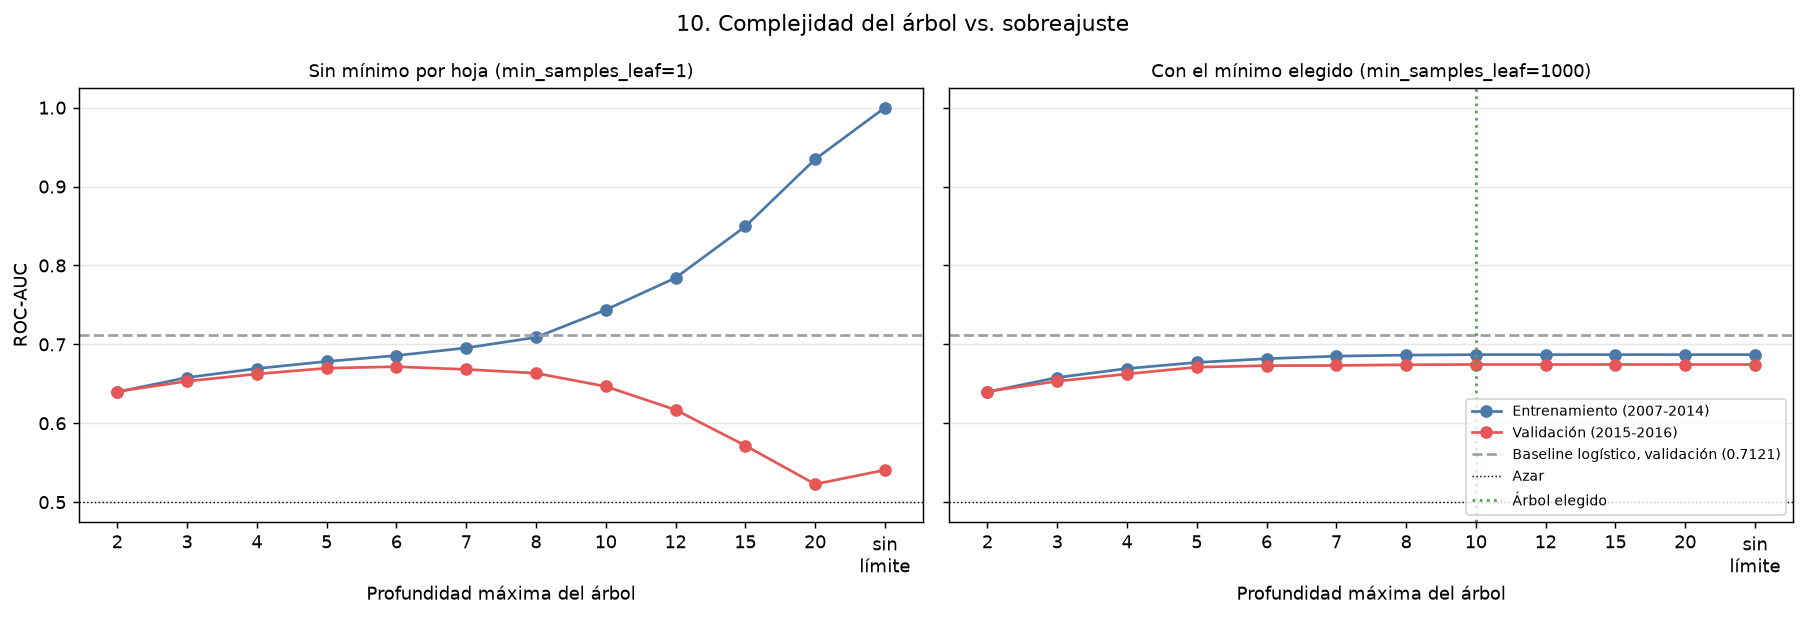

In [7]:
figuras.fig_complejidad(busqueda, parametros, auc_baseline)
display(Image(DIR_FIGURAS / "10_arbol_complejidad.png"))

**Lectura de la figura.**

- **Izquierda (sin mínimo por hoja):** a más profundidad, el entrenamiento sube
  hasta 1.0 y la validación cae. Es la firma del sobreajuste. El mejor punto
  está alrededor de profundidad 6.
- **Derecha (mínimo de 1000 por hoja):** la brecha se cierra. Exigir 1000
  préstamos por hoja impide que el árbol baje a casos individuales. Pasado
  cierto punto, la profundidad deja de importar porque el árbol ya no puede
  partir más.
- **En ningún punto** la curva roja alcanza la línea gris del baseline.

## 6. Árbol elegido vs. baseline

In [8]:
arbol, scores, res_arbol = ar.entrenar_y_evaluar(datos, parametros)
datos_precio = ar.preparar_datos(particiones, columnas_vacias, incluir_precio_lc=True)
_, _, res_precio = ar.entrenar_y_evaluar(datos_precio, parametros)

print(f"Árbol elegido: profundidad {arbol.get_depth()}, {arbol.get_n_leaves()} hojas")
resultados = {
    "clase_mayoritaria": res_logistica["clase_mayoritaria"],
    BASELINE: res_logistica[BASELINE],
    "arbol_sin_restricciones": res_libre,
    "arbol_elegido": res_arbol,
    "arbol_elegido_con_precio_lc": res_precio,
}
tabla = ev.tabla_metricas(resultados)
with pd.option_context("display.width", 160, "display.max_columns", None):
    display(tabla)

Árbol elegido: profundidad 10, 58 hojas


,modelo,conjunto,n,ROC-AUC,PR-AUC,KS,Recall,Precision,F1,Accuracy
0,clase_mayoritaria,entrenamiento,73701,0.5000,0.1687,0.0000,0.0000,0.0000,0.0000,0.8313
1,clase_mayoritaria,validacion,109382,0.5000,0.2134,0.0000,0.0000,0.0000,0.0000,0.7866
2,clase_mayoritaria,prueba,36920,0.5000,0.2125,0.0000,0.0000,0.0000,0.0000,0.7875
3,logistica_sin_indicadores,entrenamiento,73701,0.7025,0.3234,0.2966,0.6172,0.2773,0.3827,0.6641
4,logistica_sin_indicadores,validacion,109382,0.7121,0.4016,0.3071,0.6344,0.3440,0.4461,0.6637
5,logistica_sin_indicadores,prueba,36920,0.6902,0.3584,0.2825,0.5764,0.3348,0.4235,0.6667
6,arbol_sin_restricciones,entrenamiento,73701,1.0000,1.0000,1.0000,1.0000,0.1687,0.2887,0.1687
7,arbol_sin_restricciones,validacion,109382,0.5407,0.2314,0.0815,1.0000,0.2134,0.3518,0.2134
8,arbol_sin_restricciones,prueba,36920,0.5329,0.2263,0.0659,1.0000,0.2125,0.3505,0.2125
9,arbol_elegido,entrenamiento,73701,0.6870,0.2980,0.2693,0.6446,0.2584,0.3689,0.6280


  figura -> 13_comparacion_roc.png


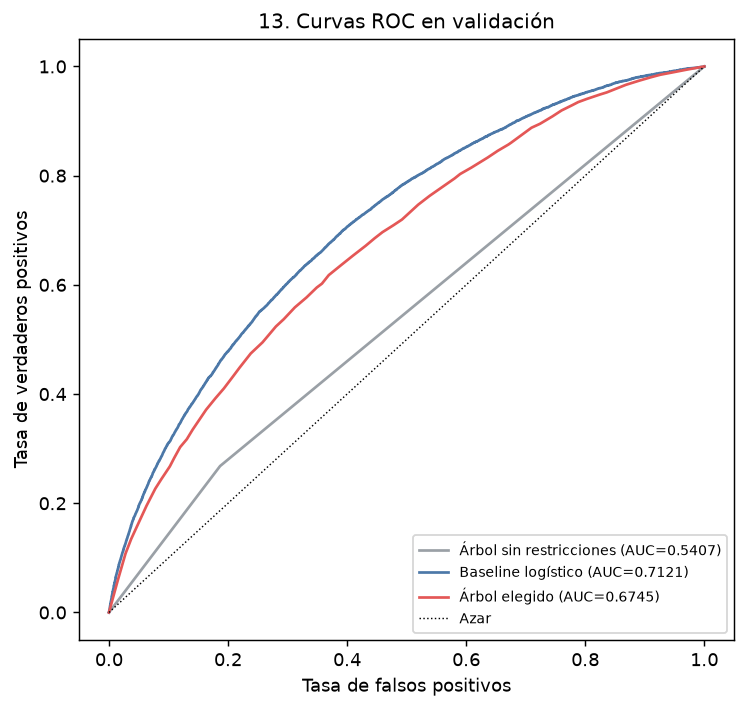

In [9]:
figuras.fig_roc([
    ("Árbol sin restricciones", datos["y"]["validacion"], scores_libre["validacion"]),
    ("Baseline logístico", *scores_logistica[BASELINE]),
    ("Árbol elegido", datos["y"]["validacion"], scores["validacion"]),
])
display(Image(DIR_FIGURAS / "13_comparacion_roc.png"))

## 7. Interpretación: las reglas del árbol

  figura -> 11_arbol_reglas.png


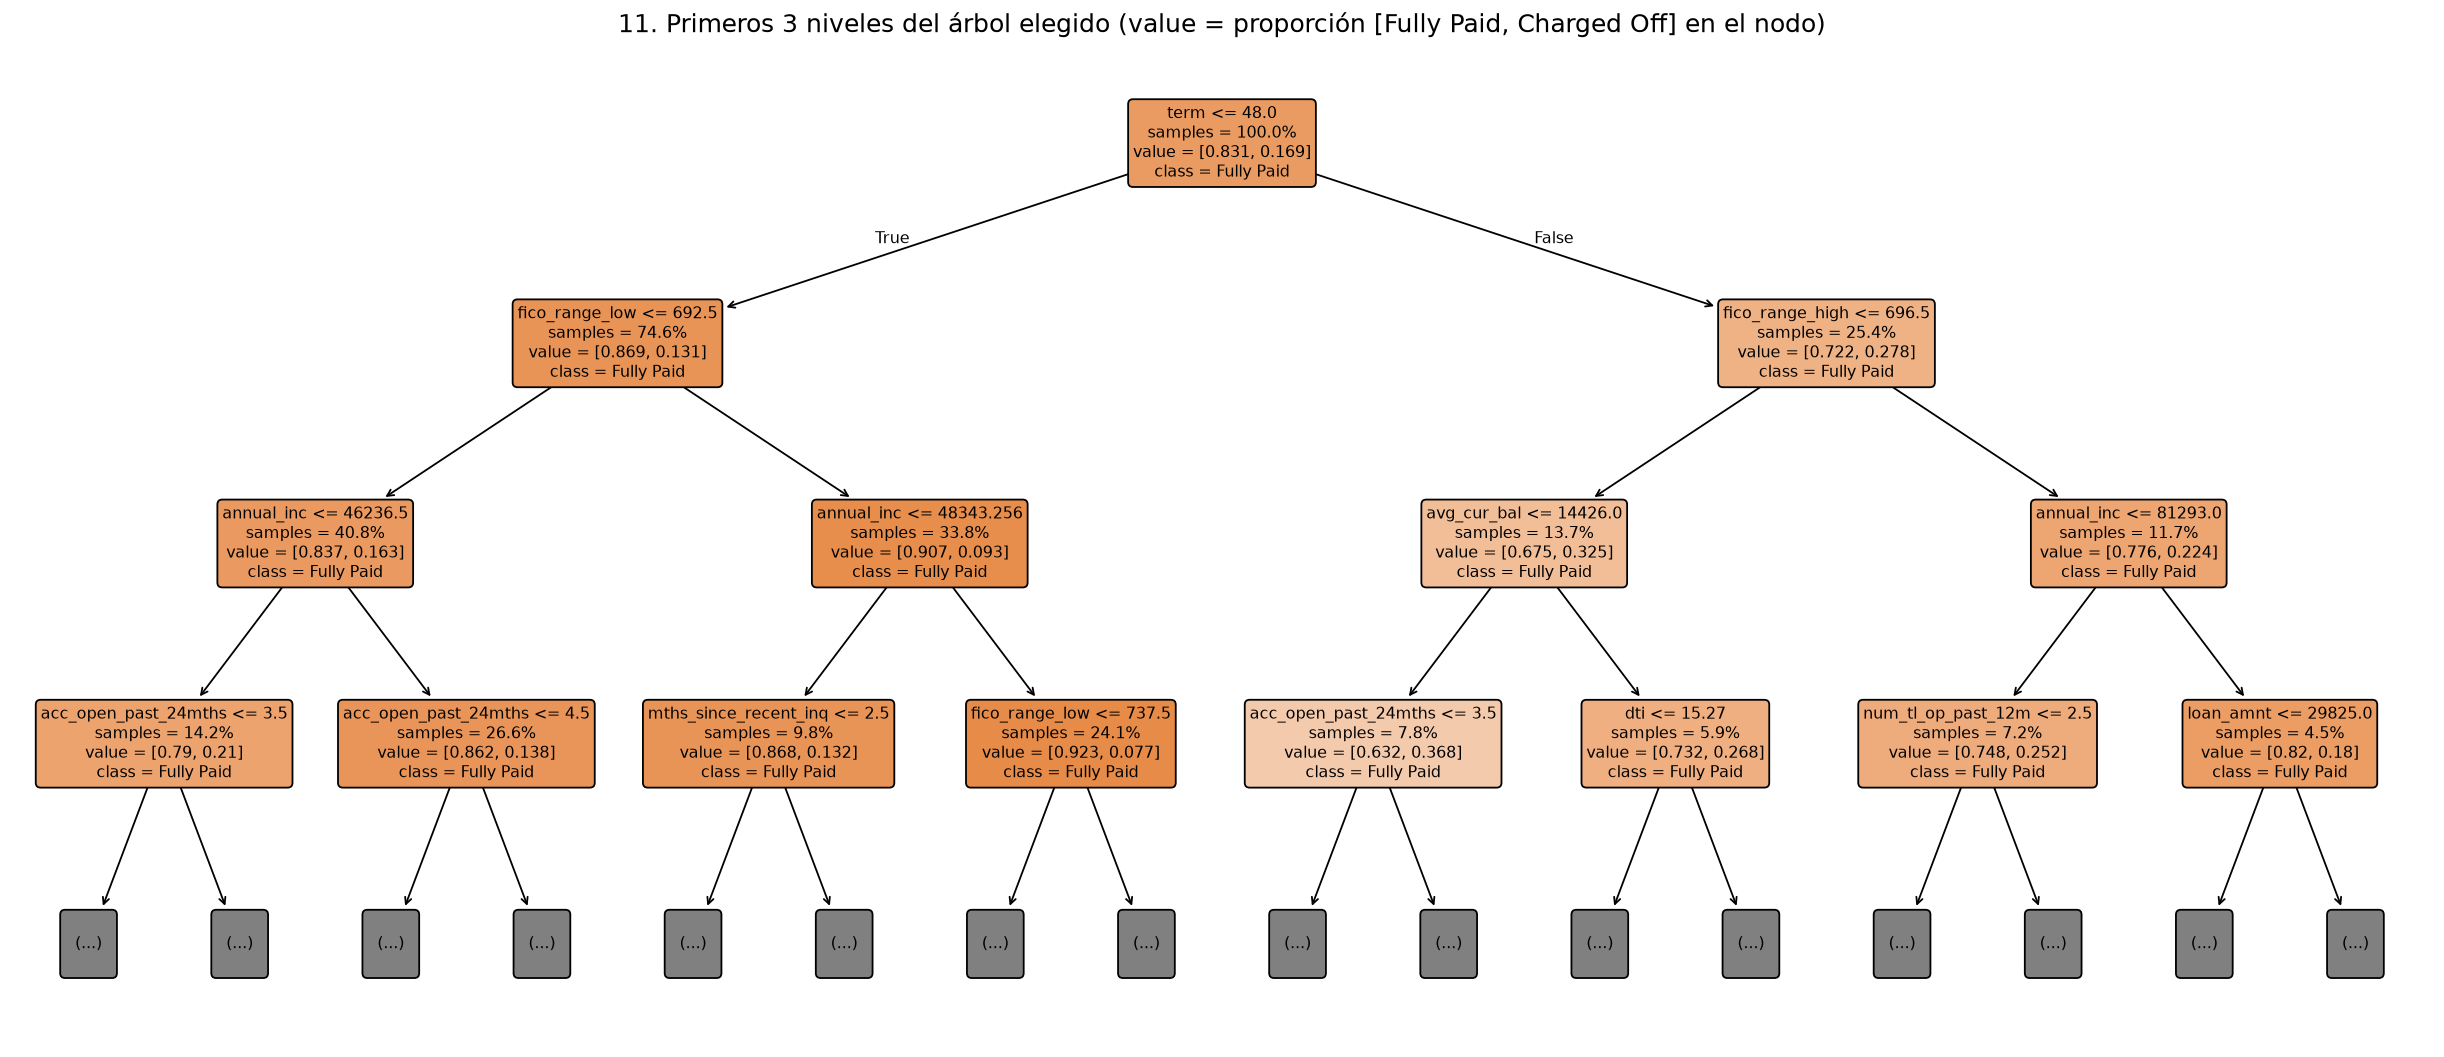

In [10]:
figuras.fig_reglas(arbol, datos["nombres"])
display(Image(DIR_FIGURAS / "11_arbol_reglas.png"))

**Cómo leer un nodo:** `value = [0.831, 0.169]` significa que en ese grupo
el 83.1 % de los préstamos se pagó y el 16.9 % cayó en default.

- **Primera pregunta: el plazo.** Con `term <= 48` (36 meses) el default es de
  13.1 %; con 60 meses sube a **27.8 %**. Es el corte que más separa.
- **Segunda pregunta: el FICO**, en las dos ramas. En 36 meses con FICO mayor a
  692 el default baja a 9.3 %.
- **Tercera: ingreso y saldos.** En 36 meses pregunta por el ingreso anual; en
  60 meses, por el saldo promedio de las cuentas. Los préstamos a 60 meses con
  FICO bajo y saldo promedio bajo llegan a **36.8 %** de default, más del doble
  del promedio.

Estas reglas se le pueden explicar a un analista de crédito sin fórmulas. Esa
es la principal ventaja del árbol frente a la regresión logística.

## 8. Importancia de variables

Usamos **importancia por permutación sobre validación**: cuánto cae el ROC-AUC
al desordenar una variable. Es más confiable que la importancia de Gini, que se
mide sobre entrenamiento y favorece a las variables con muchos valores
distintos.

  figura -> 12_arbol_importancia.png


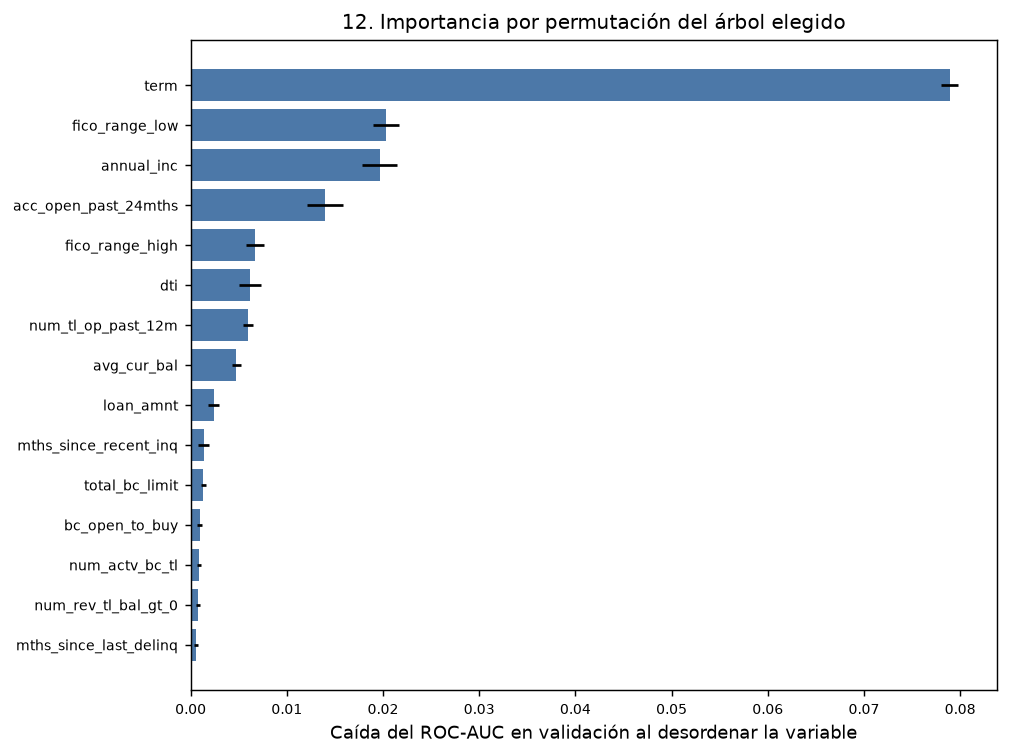

Variables con caída de AUC > 0.001: 11 de 65


,variable,caida_auc_media,caida_auc_desv
29,home_ownership,0.0,0.0
30,addr_state,0.0,0.0
31,emp_length,0.0,0.0
32,purpose,0.0,0.0


In [11]:
importancia = ar.importancia_por_permutacion(datos, arbol)
figuras.fig_importancia(importancia)
display(Image(DIR_FIGURAS / "12_arbol_importancia.png"))
print("Variables con caída de AUC > 0.001:",
      int((importancia["caida_auc_media"] > 0.001).sum()), "de", len(importancia))
display(importancia[importancia["variable"].isin(
    ["purpose", "addr_state", "home_ownership", "emp_length"])].round(4))

## 9. Lectura del resultado

**1. El árbol no supera al baseline.** ROC-AUC 0.6745 contra 0.7121 en
validación, y 0.6346 contra 0.6902 en prueba. Lo reportamos tal cual: un
modelo más flexible no es automáticamente mejor.

**2. ¿Por qué pierde?** Hay tres razones, y las tres se ven en los datos:

- **Da predicciones en escalones.** Un árbol de 58 hojas solo puede producir 58
  probabilidades distintas: todos los préstamos de una hoja reciben la misma.
  La logística da una probabilidad continua, y el riesgo crediticio cambia de
  forma gradual con el FICO, el ingreso o el DTI. Para ordenar préstamos por
  riesgo, que es lo que mide el ROC-AUC, los escalones pierden resolución.
- **Ignora las categóricas.** `purpose`, `addr_state` y `emp_length` tienen
  importancia cero en el árbol. Con 1000 préstamos mínimos por hoja, una
  categoría puntual (como `purpose = small_business`) rara vez justifica un
  corte. En la logística, en cambio, `small_business` y `emp_length` ausente
  estaban entre las variables más influyentes.
- **Se degrada más con el tiempo.** Entre validación y prueba, el árbol pierde
  0.040 de ROC-AUC y la logística solo 0.022. Los cortes fijos (`FICO <= 692`)
  son más frágiles que una pendiente cuando la población cambia de un año a
  otro.

**3. Lo que sí aporta el árbol:**

- **Interpretabilidad.** Las reglas se leen sin fórmulas y confirman lo que
  vimos en la exploración: plazo, FICO e ingreso son lo que más pesa.
- **No usa la geografía.** `addr_state` tiene importancia cero. En la propuesta
  señalamos que el estado puede actuar como proxy de nivel socioeconómico, así
  que esto es un punto a favor desde el lado ético, aunque no sea una decisión
  de diseño sino una consecuencia de las hojas grandes.
- **Una lección de control de complejidad**, que es exactamente lo que necesita
  el siguiente modelo.

**4. El precio de Lending Club.** Con `grade` e `int_rate` el árbol sube a
0.7036 en validación, cerca del baseline pero todavía por debajo. Con esas
variables el árbol reaprende la calificación de la plataforma, que ya resume
mucho del riesgo en una sola columna.

**5. Qué sigue: Gradient Boosting.** Corrige justo las dos debilidades que
encontramos. Suma cientos de árboles pequeños, así que las predicciones dejan
de ser escalones. Y cada árbol se enfoca en los errores del anterior, lo que le
permite capturar efectos que un solo árbol pasa por alto. Este árbol queda como
segunda referencia, junto al baseline, para medir cuánto aporta el boosting.

## 10. Reproducción

```bash
python -m src.run_arbol
```

Escribe `outputs/metrics_arbol.json`, `outputs/busqueda_arbol.csv`,
`outputs/importancia_arbol.csv`, `outputs/reglas_arbol.txt` y las figuras
`reports/figures/10` a `13`.